# Étape 3 : Analyse des espaces de couleur
Objectif : représenter les fèves dans plusieurs espaces de couleur (RGB, HSV, LAB, et en complément YCbCr et HLS), comparer leurs canaux et identifier l'espace qui distingue le mieux les trois catégories. L'analyse porte uniquement sur l'ensemble d'entraînement et sur les pixels de la fève (masques de l'étape 2).

In [1]:
#Chargement 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

GRAINE = 42

# Données préparées à l'étape 2
donnees = np.load("../data/donnees_feves.npz")
X, y = donnees["X"], donnees["y"]
masques = np.load("../data/masques_feves.npy").astype(bool)
df = pd.read_csv("../results/tables/02_decoupage.csv")

classes = ["category 1", "category 2", "category 3"]
idx_train = np.where(df["partition"] == "train")[0]
print("Images d'entraînement utilisées pour l'analyse :", len(idx_train))

Images d'entraînement utilisées pour l'analyse : 3576


In [2]:
# Code OpenCV de conversion pour chaque espace (None = déjà en RGB)
ESPACES = {
    "RGB":   None,
    "HSV":   cv2.COLOR_RGB2HSV,
    "LAB":   cv2.COLOR_RGB2LAB,
    "YCbCr": cv2.COLOR_RGB2YCrCb,
    "HLS":   cv2.COLOR_RGB2HLS,
}
# Noms des canaux dans l'ordre renvoyé par OpenCV
CANAUX = {
    "RGB":   ["R", "G", "B"],
    "HSV":   ["H (teinte)", "S (saturation)", "V (valeur)"],
    "LAB":   ["L* (luminosité)", "a* (vert-rouge)", "b* (bleu-jaune)"],
    "YCbCr": ["Y (luminance)", "Cr (écart rouge)", "Cb (écart bleu)"],
    "HLS":   ["H (teinte)", "L (luminosité)", "S (saturation)"],
}

def convertir(img, espace):
    """Convertit une image RGB (uint8) dans l'espace demandé."""
    if ESPACES[espace] is None:
        return img.copy()
    return cv2.cvtColor(img, ESPACES[espace])

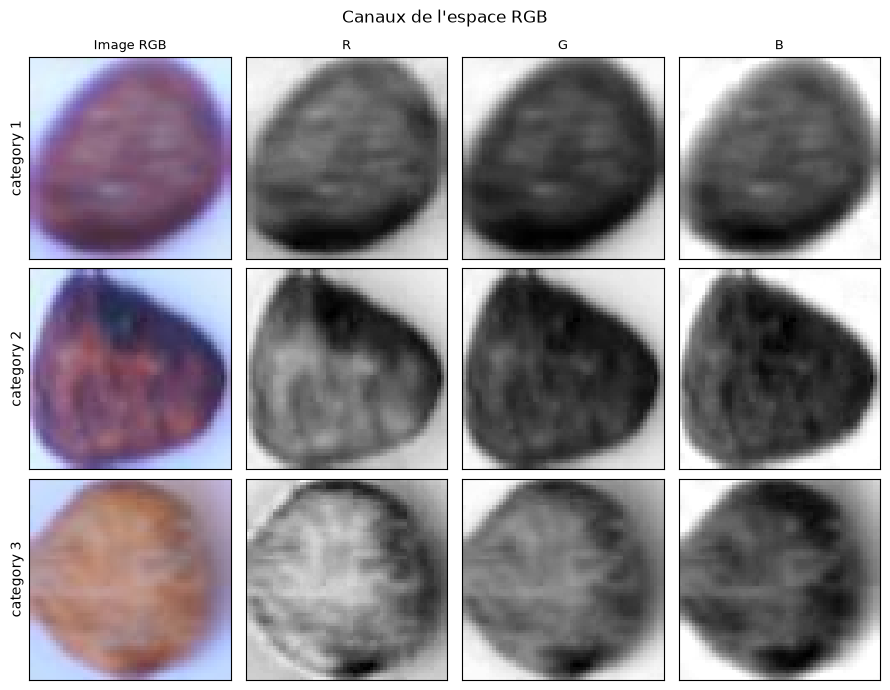

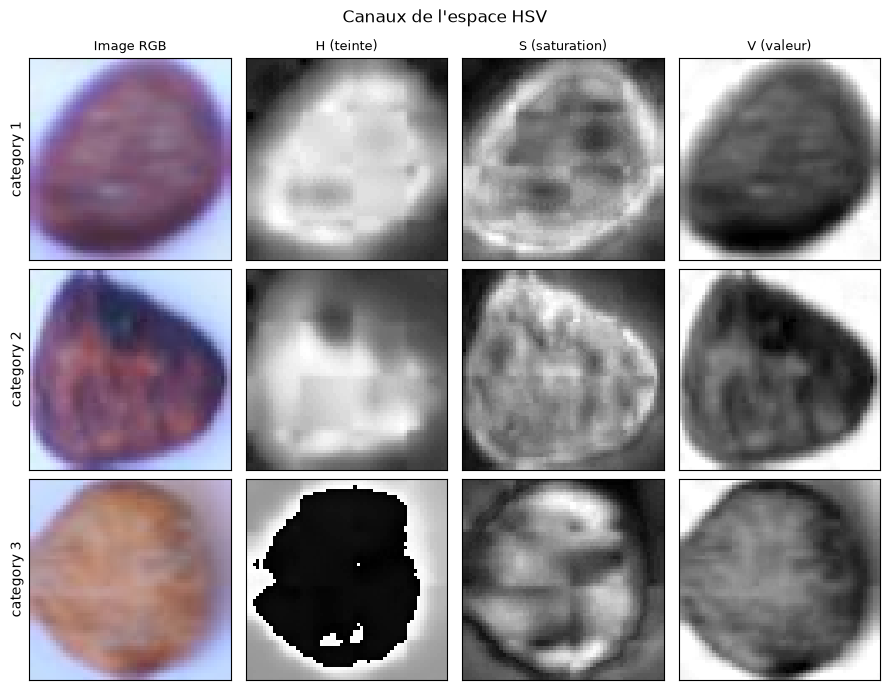

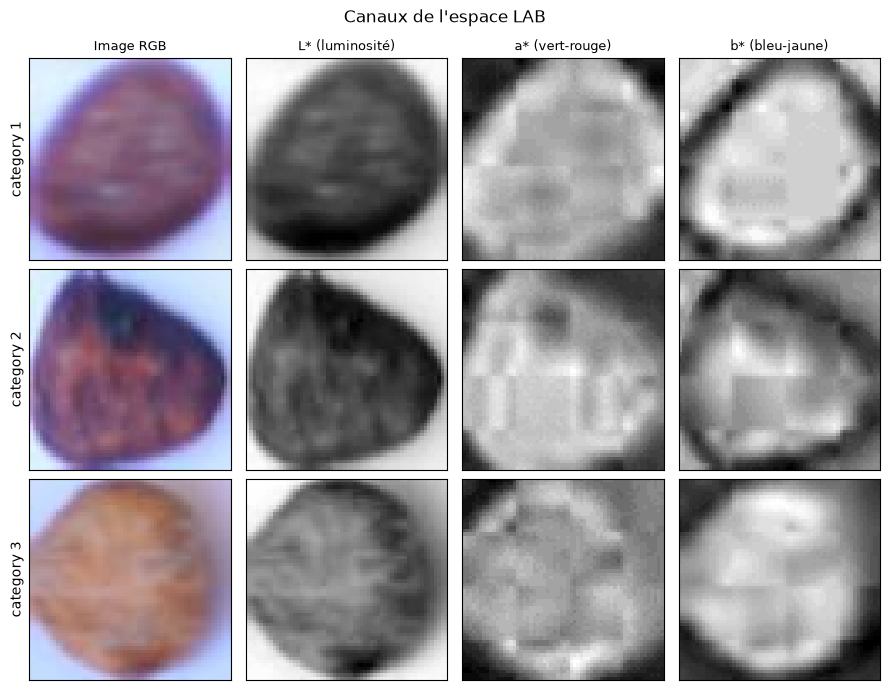

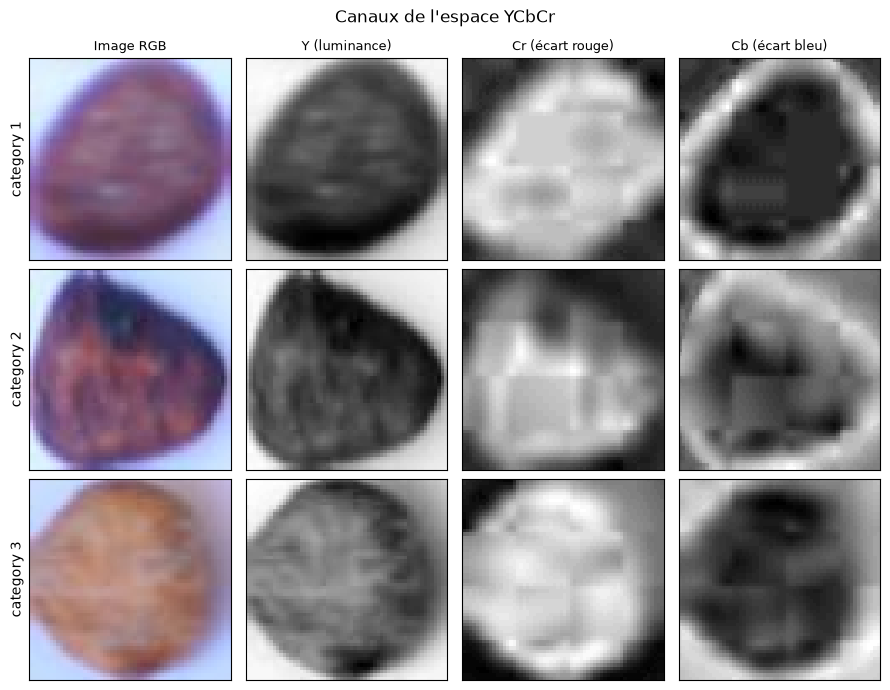

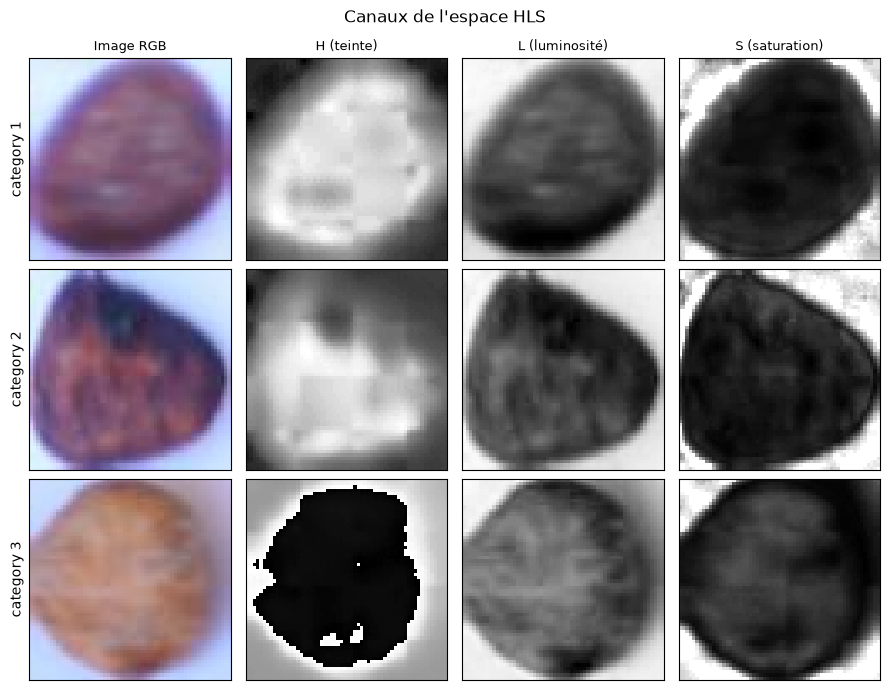

In [ ]:
#les canaux, une fève par classe
# Une fève d'entraînement au hasard pour chaque classe
rng = np.random.default_rng(GRAINE)
exemples = [rng.choice(idx_train[y[idx_train] == c]) for c in range(3)]

for espace in ESPACES:
    fig, axes = plt.subplots(3, 4, figsize=(9, 7))
    for ligne, idx in enumerate(exemples):
        img_conv = convertir(X[idx], espace)
        axes[ligne, 0].imshow(X[idx])
        axes[ligne, 0].set_ylabel(classes[ligne], fontsize=10)
        for k in range(3):
            axes[ligne, k + 1].imshow(img_conv[:, :, k], cmap="gray")
            if ligne == 0:
                axes[ligne, k + 1].set_title(CANAUX[espace][k], fontsize=9)
        axes[0, 0].set_title("Image RGB", fontsize=9)
        for ax in axes[ligne]:
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(f"Canaux de l'espace {espace}")
    plt.tight_layout()
    plt.savefig(f"../results/figures/03_canaux_{espace}.png", dpi=150)
    plt.show()

**Observations sur les canaux :**
- **RGB** : les trois canaux se ressemblent beaucoup ; ils traduisent surtout la luminosité de la fève. Ils sont fortement corrélés, ce qui limite l'information apportée par chacun. La Category 3 apparaît plus claire, surtout dans le canal R.
- **HSV / HLS – teinte (H)** : les fèves de la Category 3 apparaissent noires et celles des Categories 1 et 2 blanches. Ce contraste est en partie artificiel : la teinte est un angle, et OpenCV coupe le cercle des couleurs dans le rouge (0 = 179). Les fèves orangées (H ≈ 10) et violet-rouge (H ≈ 170) sont proches sur le cercle mais affichées aux deux extrêmes. Une rotation de la teinte sera appliquée avant de calculer des statistiques.
- **LAB – b\* (bleu-jaune)** : le fond bleuté est sombre et les fèves claires ; la Category 3, plus jaune, ressort le plus. **YCbCr – Cb** montre la même information en négatif.
- **L\*, V, Y, L** décrivent tous la luminosité : la Category 2 est la plus sombre, la Category 3 la plus claire.
- Les canaux de chrominance (a\*, b\*, Cr, Cb) montrent des **blocs de 8 × 8 pixels**, des artefacts de compression JPEG, qui compresse plus fortement la couleur que la luminosité.

In [4]:
#rotation de la teinte

def tourner_teinte(h):
    """Décale la teinte de 90 (soit 180°) pour que le rouge soit au milieu de l'échelle
    et non coupé entre 0 et 179."""
    return (h.astype(np.int16) + 90) % 180

# Exemple : deux rouges voisins avant / après rotation
print("Avant :", 5, "et", 175, "-> écart apparent de", 170)
print("Après :", tourner_teinte(np.array(5)), "et", tourner_teinte(np.array(175)), "-> écart réel de", 10)

Avant : 5 et 175 -> écart apparent de 170
Après : 95 et 85 -> écart réel de 10


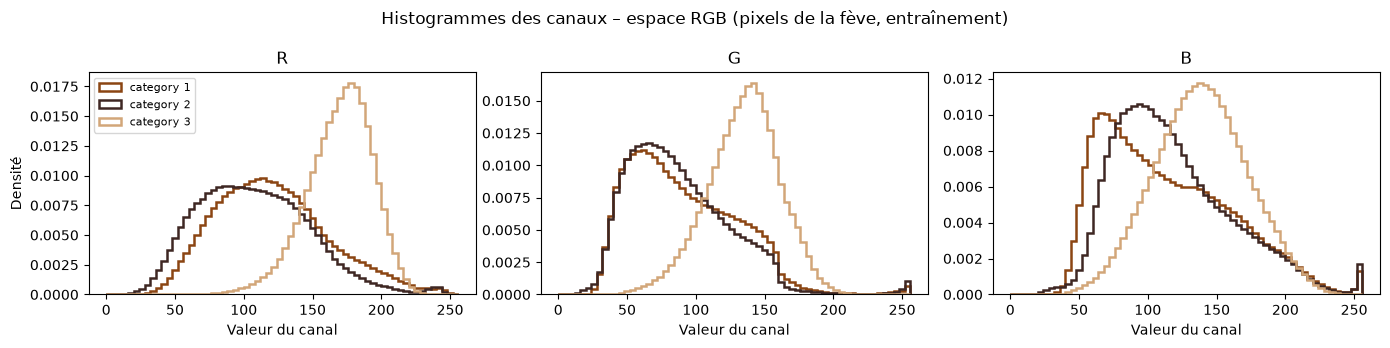

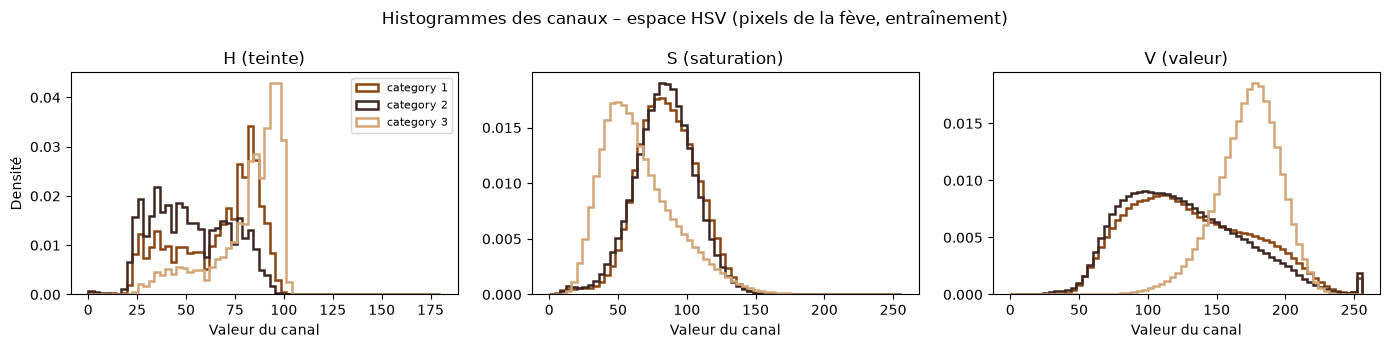

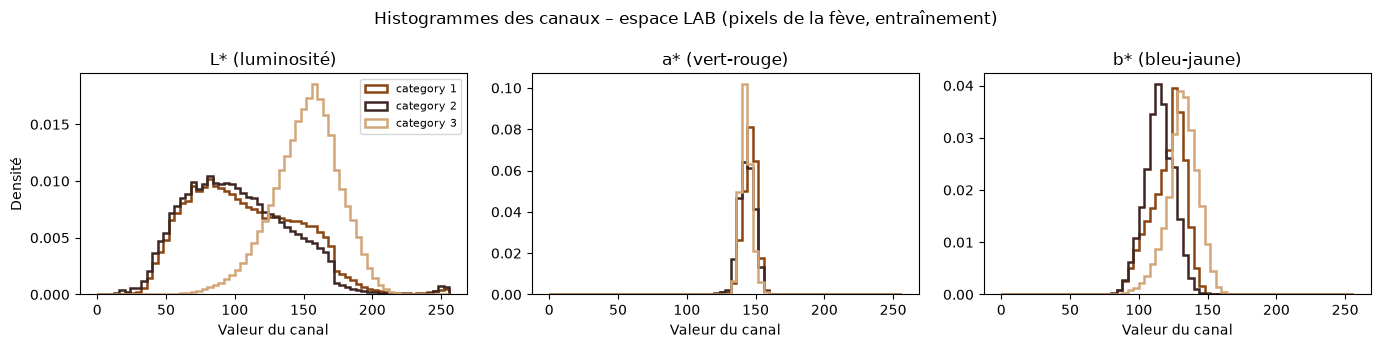

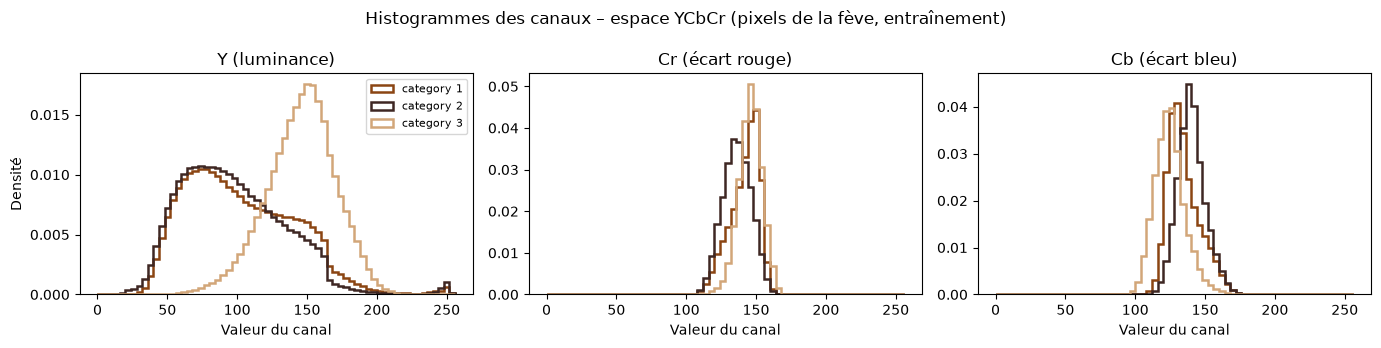

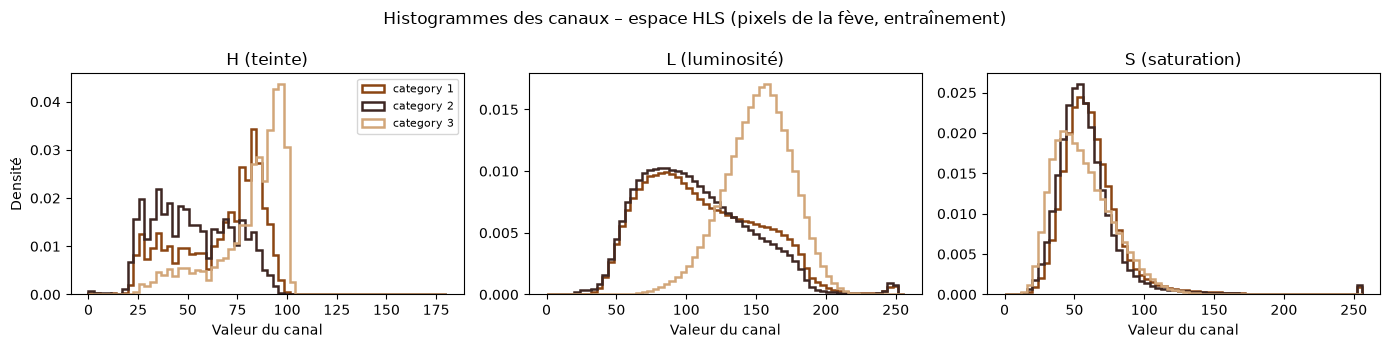

In [5]:
#histogrammes par classe (pixels de la fève uniquement)

couleurs_classes = ["#8B4513", "#3E2723", "#D2A679"]

for espace in ESPACES:
    # Conversion de toutes les images d'entraînement dans cet espace
    conv = np.array([convertir(X[i], espace) for i in idx_train])
    if espace in ["HSV", "HLS"]:
        conv[..., 0] = tourner_teinte(conv[..., 0])     # teinte corrigée

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    for k in range(3):
        borne = 180 if (espace in ["HSV", "HLS"] and k == 0) else 256
        for c in range(3):
            sel = (y[idx_train] == c)
            pixels = conv[sel][..., k][masques[idx_train][sel]]   # pixels de la fève seulement
            axes[k].hist(pixels, bins=64, range=(0, borne), density=True,
                         histtype="step", linewidth=1.8, color=couleurs_classes[c], label=classes[c])
        axes[k].set_title(CANAUX[espace][k])
        axes[k].set_xlabel("Valeur du canal")
    axes[0].set_ylabel("Densité")
    axes[0].legend(fontsize=8)
    plt.suptitle(f"Histogrammes des canaux – espace {espace} (pixels de la fève, entraînement)")
    plt.tight_layout()
    plt.savefig(f"../results/figures/03_histogrammes_{espace}.png", dpi=150)
    plt.show()

**Lecture des histogrammes :**
- La **Category 3** se distingue nettement par sa luminosité (R, G, V, L\*, Y, L) et par une teinte orangée très concentrée.
- Les **Categories 1 et 2** se superposent presque parfaitement sur tous les canaux de luminosité. Elles ne se séparent que sur les canaux qui décrivent la nuance bleu-violet : **b\*** (Category 2 décalée vers le bleu), **Cb** (même information en miroir) et la **teinte H** (Category 2 plus violacée, Category 1 plus rouge). La Category 2 n'est donc pas seulement plus sombre : elle est plus violacée.
- Le canal **a\*** est très peu discriminant : les trois distributions sont confondues.
- Le pic à 255 sur certains canaux correspond aux reflets lumineux (pixels saturés).
- Prudence : le liseré bleuté laissé par la segmentation peut accentuer légèrement la nuance violacée mesurée.

In [7]:
#score F de chaque canal
#F = (écart entre les moyennes des classes) / (dispersion à l’intérieur de chaque classe)

from sklearn.feature_selection import f_classif

y_tr = y[idx_train]
m_tr = masques[idx_train]
paire = (y_tr < 2)            # images des catégories 1 et 2 seulement
lignes = []

for espace in ESPACES:
    conv = np.array([convertir(X[i], espace) for i in idx_train])
    if espace in ["HSV", "HLS"]:
        conv[..., 0] = tourner_teinte(conv[..., 0])

    # Moyenne de chaque canal sur la fève, pour chaque image -> tableau (3576, 3)
    moyennes = np.array([[img[..., k][m].mean() for k in range(3)] for img, m in zip(conv, m_tr)])

    F_3, _ = f_classif(moyennes, y_tr)
    F_12, _ = f_classif(moyennes[paire], y_tr[paire])
    for k in range(3):
        lignes.append({"Espace": espace, "Canal": CANAUX[espace][k],
                       "F (3 classes)": F_3[k], "F (cat. 1 vs 2)": F_12[k]})

df_F = pd.DataFrame(lignes).round(0)
df_F.to_csv("../results/tables/03_score_F_canaux.csv", index=False)
df_F.sort_values("F (cat. 1 vs 2)", ascending=False)

,Espace,Canal,F (3 classes),F (cat. 1 vs 2)
12,HLS,H (teinte),2549.0,1421.0
3,HSV,H (teinte),2549.0,1420.0
8,LAB,b* (bleu-jaune),2634.0,1144.0
11,YCbCr,Cb (écart bleu),2635.0,1079.0
10,YCbCr,Cr (écart rouge),909.0,786.0
7,LAB,a* (vert-rouge),272.0,349.0
0,RGB,R,1336.0,146.0
14,HLS,S (saturation),104.0,117.0
5,HSV,V (valeur),1152.0,49.0
6,LAB,L* (luminosité),1347.0,37.0


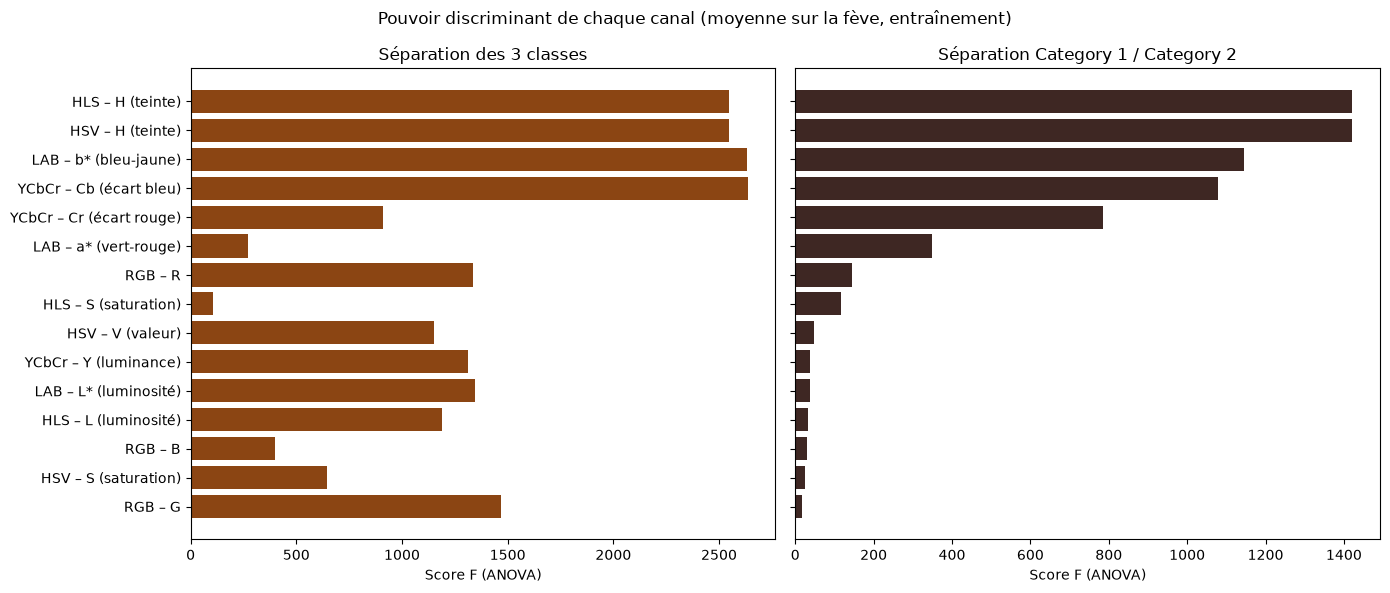

In [8]:
#graphique comparatif

df_trie = df_F.assign(Nom=df_F["Espace"] + " – " + df_F["Canal"]).sort_values("F (cat. 1 vs 2)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(df_trie["Nom"], df_trie["F (3 classes)"], color="#8B4513")
axes[0].set_title("Séparation des 3 classes")
axes[1].barh(df_trie["Nom"], df_trie["F (cat. 1 vs 2)"], color="#3E2723")
axes[1].set_title("Séparation Category 1 / Category 2")
for ax in axes:
    ax.set_xlabel("Score F (ANOVA)")
plt.suptitle("Pouvoir discriminant de chaque canal (moyenne sur la fève, entraînement)")
plt.tight_layout()
plt.savefig("../results/figures/03_score_F_canaux.png", dpi=150)
plt.show()

In [9]:
#L'effet de la correction de la teinte

# Score F de la teinte SANS correction, pour comparaison
H_brut = np.array([convertir(X[i], "HSV")[..., 0] for i in idx_train])
moy_brut = np.array([[h[m].mean()] for h, m in zip(H_brut, m_tr)])

F_brut_3, _ = f_classif(moy_brut, y_tr)
F_brut_12, _ = f_classif(moy_brut[paire], y_tr[paire])
print(f"Teinte brute     -> F (3 classes) = {F_brut_3[0]:.0f} | F (cat. 1 vs 2) = {F_brut_12[0]:.0f}")
print(f"Teinte corrigée  -> F (3 classes) = 2549 | F (cat. 1 vs 2) = 1420")

Teinte brute     -> F (3 classes) = 1360 | F (cat. 1 vs 2) = 18
Teinte corrigée  -> F (3 classes) = 2549 | F (cat. 1 vs 2) = 1420


**Pouvoir discriminant des canaux :**
- Les canaux de **luminosité** (L\*, V, Y, L, R, G) séparent bien la Category 3 (F > 1 100) mais sont **presque inutiles pour distinguer les Categories 1 et 2** (F < 150).
- Les canaux de **chrominance** — teinte H, b\*, Cb, Cr — sont les seuls à bien séparer les Categories 1 et 2 (F entre 786 et 1 421), tout en restant très efficaces sur les trois classes.
- **RGB** est l'espace le moins adapté à la paire difficile : chaque canal y mélange couleur et luminosité.
- La **correction de la teinte** est indispensable : sans elle, le score F de la teinte pour les Categories 1 / 2 n'est que de **18** (contre **1 420** après correction, soit environ 80 fois plus), et de 1 360 contre 2 549 pour les trois classes. Sans cette correction, on aurait conclu à tort que la teinte était inutile.

## Conclusion de l'étape 3

**Quel espace colorimétrique représente le mieux les fèves ?** Les espaces qui séparent la luminosité de la couleur — **HSV** (grâce à la teinte), **LAB** (grâce à b\*) et, en complément, **YCbCr** (grâce à Cb) — sont nettement plus discriminants que **RGB**, en particulier pour la paire la plus difficile (Category 1 / Category 2).

**Deux informations complémentaires :** la **luminosité** distingue la Category 3 (fèves claires), tandis que la **nuance bleu-violet** distingue la Category 2 de la Category 1. Combiner un espace de couleur avec un autre devrait donc apporter des informations complémentaires. Cette hypothèse sera testée à l'étape 5 (expériences E1 à E7).

**Points de méthode :** l'analyse a été faite uniquement sur l'ensemble d'entraînement et sur les pixels de la fève ; la teinte a été corrigée pour tenir compte de son caractère circulaire ; des artefacts de compression JPEG (blocs 8 × 8) sont visibles dans les canaux de chrominance.